<h2>Brain Tumor Detection</h2>

<table>
  <tr>
    <th>Student Name</th>
    <th>Roll Number</th>
    <th>Class</th>
    <th>Submitted to</th>
    <th>Course</th>
  </tr>
  <tr>
    <td>Dawood Shahzad</td>
    <td>02-136221-034</td>
    <td>BSAI-5A</td>
    <td>Miss Munaza Saad</td>
    <td>Machine Learning CCP</td>
  </tr>
  <tr>
    <td>Usama Raheem</td>
    <td>02-136221-032</td>
    <td>BSAI-5A</td>
    <td>Miss Munaza Saad</td>
    <td>Machine Learning CCP</td>
  </tr>
</table>

# Import needed modules

In [2]:
# importing system libs
import os # for file path and directory operations
import time # for time-related functions
import shutil # for file copying and moving
import pathlib # for working with file paths and directories
import itertools # for creating iterators for efficient looping
from PIL import Image # for image processing

# importing data handling tools
import cv2 # for computer vision and image processing
import numpy as np # for numerical computations
import pandas as pd # for data manipulation and analysis
import seaborn as sns # for data visualization
sns.set_style('darkgrid') # seaborn plot style
import matplotlib.pyplot as plt # for data visualization
from sklearn.model_selection import train_test_split # for splitting data into training and testing sets
from sklearn.metrics import confusion_matrix, classification_report # for evaluating model performance

# importing Deep learning Libraries
import tensorflow as tf # for building neural networks
from tensorflow import keras # for building neural networks
from tensorflow.keras.models import Sequential # for building sequential neural networks
from tensorflow.keras.optimizers import Adam, Adamax # for optimizing neural network training
from tensorflow.keras.preprocessing.image import ImageDataGenerator # for generating images for training
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization # for building neural network layers
from tensorflow.keras import regularizers # for regularization techniques

# Ignore Warnings
import warnings # for handling warning messages
warnings.filterwarnings("ignore") # ignore all warning messages
print ('modules loaded') 

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


modules loaded


# **Data Preprocessing**

### **Reading data and storing it in dataframe**

In [3]:
# Define the directory containing the brain tumor dataset
data_dir = '/content/brain_tumor_dataset'

# Initialize empty lists to store file paths and labels
filepaths = []
labels = []

# Get the list of folder names (each representing a class)
folds = os.listdir(data_dir)

# Iterate over each class folder
for fold in folds:
    # Create the full path to the current class folder
    foldpath = os.path.join(data_dir, fold)
    # Get the list of files in the current class folder
    filelist = os.listdir(foldpath)
    # Iterate over each file in the class folder
    for file in filelist:
        # Create the full path to the current file
        fpath = os.path.join(foldpath, file)
        
        # Append the file path to the filepaths list
        filepaths.append(fpath)
        # Append the class label (folder name) to the labels list
        labels.append(fold)
        
# Convert the file paths and labels lists into Pandas Series
Fseries = pd.Series(filepaths, name='filepaths')
Lseries = pd.Series(labels, name='labels')

# Concatenate the Series into a single DataFrame
df = pd.concat([Fseries, Lseries], axis=1)


### **Split data into train, valid, and test**

In [5]:
# Define the stratification criteria based on the 'labels' column
strat = df['labels']

# Split the DataFrame into training and testing sets
# Ensure the training set size is 80% of the original data
# Enable shuffling of the data before splitting
# Set a random seed for reproducibility
# Use stratification to ensure each set has the same label distribution as the original data
train_df, test_df = train_test_split(df, train_size=0.8, shuffle=True, random_state=123, stratify=strat)


### **Create image data generator**

In [6]:
# Define the batch size for the data generator
batch_size = 8

# Define the target image size for resizing the images
img_size = (224, 224)

# Define the number of channels in the images (RGB)
channels = 3

# Define the full image shape
img_shape = (img_size[0], img_size[1], channels)

# Initialize the ImageDataGenerator for training data
tr_gen = ImageDataGenerator()

# Initialize the ImageDataGenerator for testing data
ts_gen = ImageDataGenerator()

# Create a data generator for the training set
train_gen = tr_gen.flow_from_dataframe(
    train_df,  # DataFrame containing training data file paths and labels
    x_col='filepaths',  # Column name in DataFrame with the file paths
    y_col='labels',  # Column name in DataFrame with the labels
    target_size=img_size,  # Resize images to the specified target size
    class_mode='categorical',  # One-hot encode the labels
    color_mode='rgb',  # Use RGB color mode
    shuffle=True,  # Shuffle the data before each epoch
    batch_size=batch_size  # Number of images to return in each batch
)

# Create a data generator for the testing set
test_gen = ts_gen.flow_from_dataframe(
    test_df,  # DataFrame containing testing data file paths and labels
    x_col='filepaths',  # Column name in DataFrame with the file paths
    y_col='labels',  # Column name in DataFrame with the labels
    target_size=img_size,  # Resize images to the specified target size
    class_mode='categorical',  # One-hot encode the labels
    color_mode='rgb',  # Use RGB color mode
    shuffle=False,  # Do not shuffle the data before each epoch
    batch_size=batch_size  # Number of images to return in each batch
)


Found 202 validated image filenames belonging to 2 classes.
Found 51 validated image filenames belonging to 2 classes.


### **Show sample from train data**

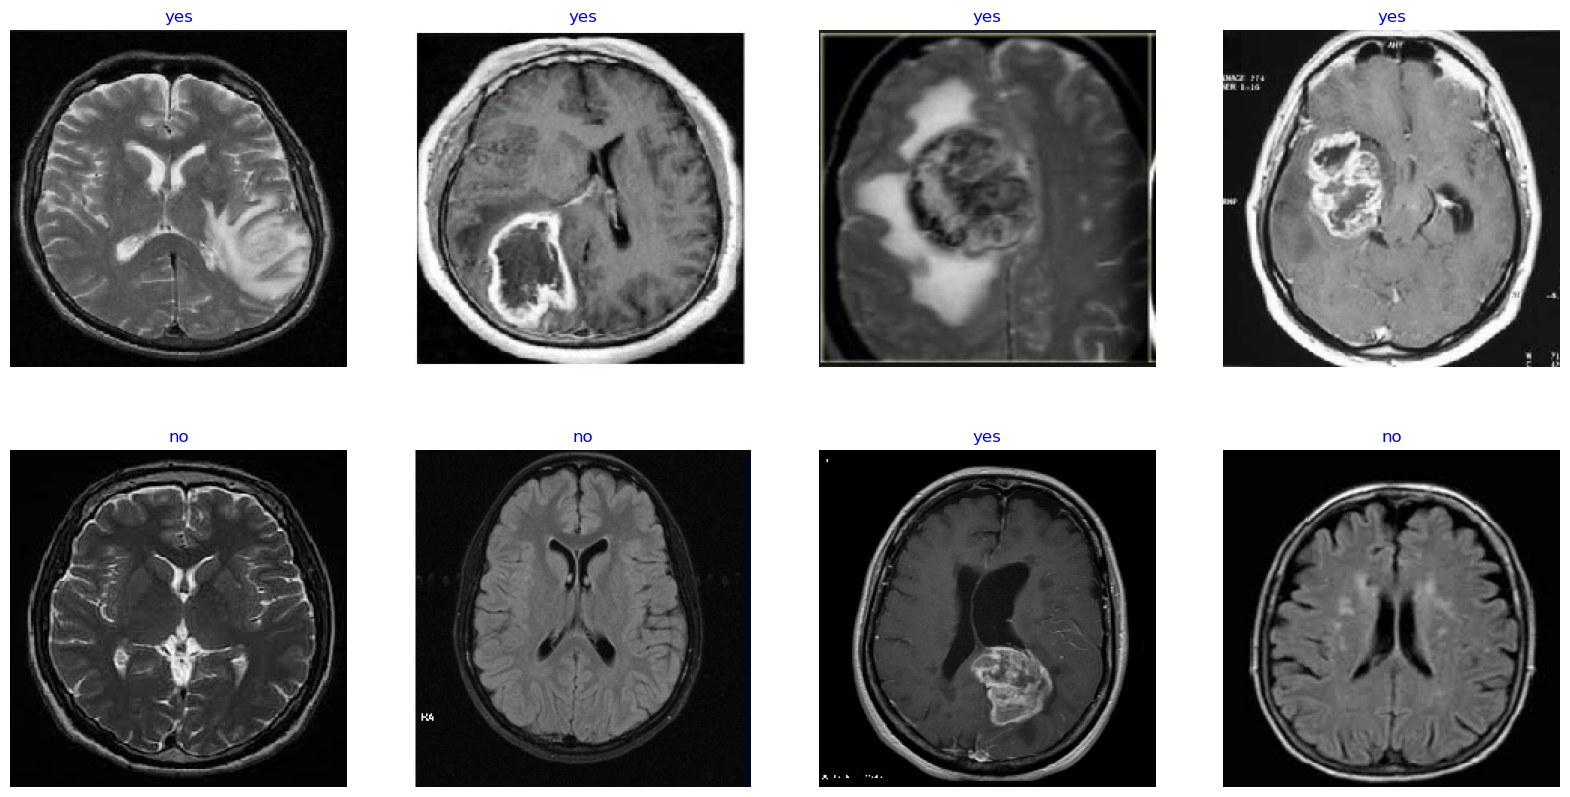

In [7]:
g_dict = train_gen.class_indices      # defines dictionary {'class': index}
classes = list(g_dict.keys())       # defines list of dictionary's kays (classes), classes names : string
images, labels = next(train_gen)      # get a batch size samples from the generator

plt.figure(figsize= (20, 10))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    image = images[i] / 255       # scales data to range (0 - 255)
    plt.imshow(image)
    index = np.argmax(labels[i])  # get image index
    class_name = classes[index]   # get class of image
    plt.title(class_name, color= 'blue', fontsize= 12)
    plt.axis('off')
plt.show()

# **Model Structure**

#### **Generic Model Creation**

In [8]:
# Define image size
img_size = (224, 224)
# Define number of channels in the image (RGB)
channels = 3
# Define the shape of the input image
img_shape = (img_size[0], img_size[1], channels)
# Determine the number of classes based on the number of unique labels in the training data
class_count = len(list(train_gen.class_indices.keys())) 

# Create a pre-trained model (You can use models like EfficientNet, VGG, ResNet)
# Here, we're using EfficientNetB3 from the EfficientNet family.
base_model = tf.keras.applications.efficientnet.EfficientNetB3(include_top=False, weights="imagenet", 
                                                               input_shape=img_shape, pooling='max')

# Construct the complete model architecture
model = Sequential([
    base_model,  # Add the pre-trained base model
    BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001),  # Batch normalization layer
    Dense(256,  # Fully connected layer with 256 units
          kernel_regularizer=regularizers.l2(l=0.016),  # Apply L2 regularization to the kernel weights
          activity_regularizer=regularizers.l1(0.006),  # Apply L1 regularization to the activity
          bias_regularizer=regularizers.l1(0.006),  # Apply L1 regularization to the bias
          activation='relu'),  # Activation function ReLU
    Dropout(rate=0.45, seed=123),  # Dropout layer to prevent overfitting
    Dense(class_count, activation='softmax')  # Output layer with softmax activation for classification
])

# Compile the model with optimizer, loss function, and evaluation metrics
model.compile(Adamax(learning_rate=0.001),  # Optimizer Adamax with learning rate 0.001
              loss='categorical_crossentropy',  # Loss function for categorical classification
              metrics=['accuracy'])  # Evaluation metric to monitor during training

# Display model summary
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 efficientnetb3 (Functional)  (None, 1536)             10783535  
                                                                 
 batch_normalization (BatchN  (None, 1536)             6144      
 ormalization)                                                   
                                                                 
 dense (Dense)               (None, 256)               393472    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 2)                 514       
                                                                 
Total params: 11,183,665
Trainable params: 11,093,290
Non-trainable params: 90,375
_______________________________________

#### **Train model**

In [9]:
epochs = 30   # number of all epochs or passes in training

history = model.fit(x= train_gen, epochs= epochs, verbose= 1, validation_data= test_gen, 
                    validation_steps= None, shuffle= False)

Epoch 1/30
26/26 [==============================] - 24s 275ms/step - loss: 8.2593 - accuracy: 0.7525 - val_loss: 9.1887 - val_accuracy: 0.6078
Epoch 2/30
26/26 [==============================] - 4s 169ms/step - loss: 7.4990 - accuracy: 0.7970 - val_loss: 9.2401 - val_accuracy: 0.6863
Epoch 3/30
26/26 [==============================] - 4s 158ms/step - loss: 6.6979 - accuracy: 0.9059 - val_loss: 7.0038 - val_accuracy: 0.8627
Epoch 4/30
26/26 [==============================] - 4s 158ms/step - loss: 6.2294 - accuracy: 0.9257 - val_loss: 6.5432 - val_accuracy: 0.9216
Epoch 5/30
26/26 [==============================] - 4s 156ms/step - loss: 6.0475 - accuracy: 0.9010 - val_loss: 6.0367 - val_accuracy: 0.9216
Epoch 6/30
26/26 [==============================] - 4s 155ms/step - loss: 5.6091 - accuracy: 0.9554 - val_loss: 5.7862 - val_accuracy: 0.9216
Epoch 7/30
26/26 [==============================] - 4s 156ms/step - loss: 5.4463 - accuracy: 0.9307 - val_loss: 5.6487 - val_accuracy: 0.8824
Epoch

#### **Display model performance**

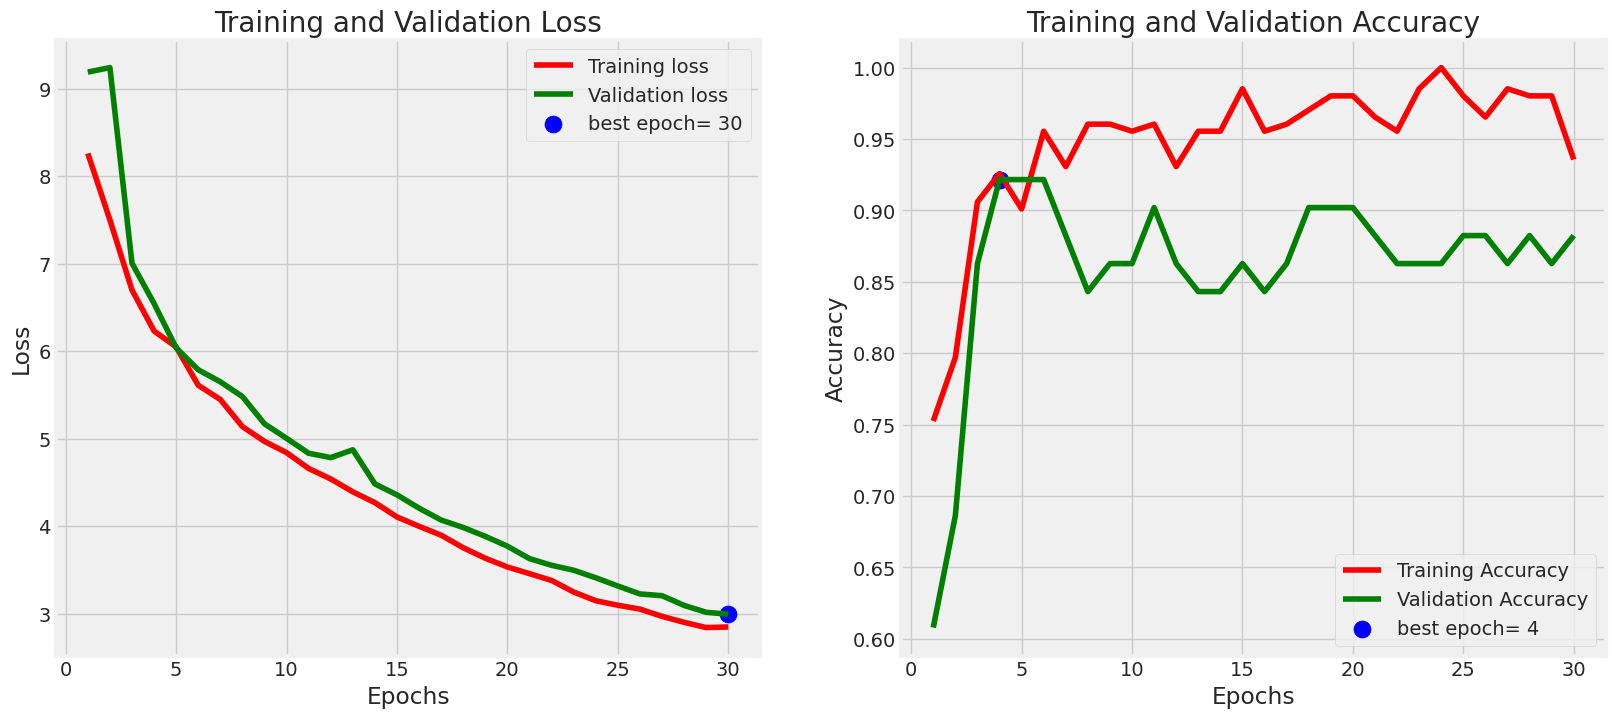

In [10]:
# Extract training accuracy from the history object
tr_acc = history.history['accuracy']

# Extract training loss from the history object
tr_loss = history.history['loss']

# Extract validation accuracy from the history object
val_acc = history.history['val_accuracy']

# Extract validation loss from the history object
val_loss = history.history['val_loss']

# Find the index of the epoch with the lowest validation loss
index_loss = np.argmin(val_loss)

# Get the lowest validation loss value
val_lowest = val_loss[index_loss]

# Find the index of the epoch with the highest validation accuracy
index_acc = np.argmax(val_acc)

# Get the highest validation accuracy value
acc_highest = val_acc[index_acc]

# Create a list of epoch numbers
Epochs = [i + 1 for i in range(len(tr_acc))]

# Define a label for the best epoch based on the lowest validation loss
loss_label = f'best epoch= {str(index_loss + 1)}'

# Define a label for the best epoch based on the highest validation accuracy
acc_label = f'best epoch= {str(index_acc + 1)}'


# Plot training history
plt.figure(figsize= (20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout
plt.show()

# **Evaluate model**

In [12]:
train_score = model.evaluate(train_gen, verbose= 1)
test_score = model.evaluate(test_gen, verbose= 1)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

7/7 [==============================] - 0s 29ms/step - loss: 2.9928 - accuracy: 0.8824
Train Loss:  2.7419683933258057
Train Accuracy:  0.9950494766235352
--------------------
Test Loss:  2.99277925491333
Test Accuracy:  0.8823529481887817


# **Get Predictions**

In [13]:
preds = model.predict_generator(test_gen)
y_pred = np.argmax(preds, axis=1)

#### **Confusion Matrics and Classification Report**

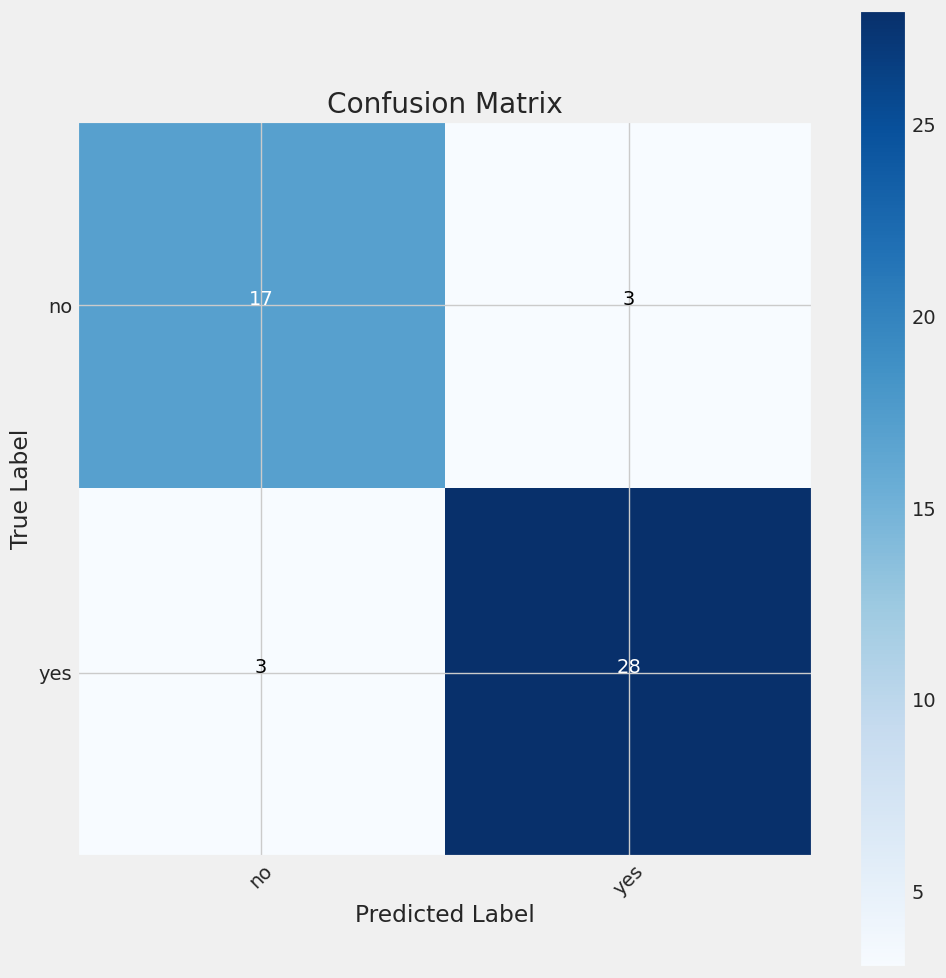

In [14]:
g_dict = test_gen.class_indices
classes = list(g_dict.keys())

# Confusion matrix
cm = confusion_matrix(test_gen.classes, y_pred)

plt.figure(figsize= (10, 10))
plt.imshow(cm, interpolation= 'nearest', cmap= plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()

tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation= 45)
plt.yticks(tick_marks, classes)


thresh = cm.max() / 2.
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, cm[i, j], horizontalalignment= 'center', color= 'white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.show()

In [15]:
# Classification report
print(classification_report(test_gen.classes, y_pred, target_names= classes))

              precision    recall  f1-score   support

          no       0.85      0.85      0.85        20
         yes       0.90      0.90      0.90        31

    accuracy                           0.88        51
   macro avg       0.88      0.88      0.88        51
weighted avg       0.88      0.88      0.88        51



#### **Save model**

In [16]:
#Save the model
model.save('Model.h5')